<a href="https://colab.research.google.com/github/anupjha95581-ai/vibration-predictive-maintenance/blob/main/mqtt_alternate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install paho-mqtt

import time
import paho.mqtt.client as mqtt

BASE  = "vibmon_AJ_4827"        # <-- the first part of the topic in your sketch
TOPIC = BASE + "/#"                   # listen to everything under it
msgs  = []

def on_connect(client, userdata, flags, reason_code, properties=None):
    print("Connected to broker, reason code:", reason_code)
    client.subscribe(TOPIC)
    # Self-test: Colab sends itself one message to prove the path works
    client.publish(BASE + "/colab_test", "hello from colab")

def on_message(client, userdata, m):
    text = m.payload.decode(errors="replace")
    msgs.append((m.topic, text))
    print(m.topic, "->", text)

client = mqtt.Client(mqtt.CallbackAPIVersion.VERSION2)
client.on_connect = on_connect
client.on_message = on_message

print("Connecting...")
client.connect("broker.hivemq.com", 1883, 60)

client.loop_start()
time.sleep(60)                         # listen for 60 seconds
client.loop_stop()
client.disconnect()

print("\nTotal messages received:", len(msgs))
print("From the ESP32:", sum(1 for t, _ in msgs if t.endswith("/features")))

Connecting...
Connected to broker, reason code: Success
vibmon_AJ_4827/colab_test -> hello from colab
vibmon_AJ_4827/node1/features -> {"n":603,"truth":"healthy","rms":0.9052,"kurt":1.520,"crest":1.584,"p2p":2.848,"p1x":0.81407,"p2x":0.00017,"p3x":0.00020,"ratio":0.0005}
vibmon_AJ_4827/node1/features -> {"n":604,"truth":"healthy","rms":0.7397,"kurt":1.614,"crest":1.810,"p2p":2.635,"p1x":0.53570,"p2x":0.00100,"p3x":0.00090,"ratio":0.0036}
vibmon_AJ_4827/node1/features -> {"n":605,"truth":"imbalance","rms":1.5144,"kurt":1.504,"crest":1.500,"p2p":4.537,"p1x":2.30046,"p2x":0.00013,"p3x":0.00026,"ratio":0.0002}
vibmon_AJ_4827/node1/features -> {"n":606,"truth":"misalign","rms":1.0165,"kurt":1.691,"crest":1.751,"p2p":3.480,"p1x":0.78735,"p2x":0.18895,"p3x":0.04677,"ratio":0.2994}
vibmon_AJ_4827/node1/features -> {"n":607,"truth":"healthy","rms":0.5667,"kurt":1.551,"crest":1.797,"p2p":1.971,"p1x":0.31475,"p2x":0.00017,"p3x":0.00024,"ratio":0.0013}
vibmon_AJ_4827/node1/features -> {"n":608,"tr

In [ ]:
!pip -q install paho-mqtt

import json
import time
import pandas as pd
import paho.mqtt.client as mqtt

BASE        = "vibmon_AJ_4827"
TOPIC       = BASE + "/node1/features"
TARGET      = 600          # windows to collect
MAX_SECONDS = 1800         # give up after 30 minutes

rows  = []
state = {"last_n": -1, "session": 0}

def on_connect(client, userdata, flags, reason_code, properties=None):
    print("Connected, reason code:", reason_code)
    client.subscribe(TOPIC)

def on_message(client, userdata, m):
    try:
        d = json.loads(m.payload.decode())
    except Exception as e:
        print("Skipped a bad message:", e)
        return
    # If the sketch was restarted, n goes back to 0: start a new session id
    if d.get("n", 0) <= state["last_n"]:
        state["session"] += 1
    state["last_n"] = d.get("n", 0)
    d["session"]   = state["session"]
    d["recv_time"] = time.time()
    rows.append(d)
    if len(rows) % 50 == 0:
        print(len(rows), "windows collected")

client = mqtt.Client(mqtt.CallbackAPIVersion.VERSION2)
client.on_connect = on_connect
client.on_message = on_message
client.connect("broker.hivemq.com", 1883, 60)

t0 = time.time()
client.loop_start()
while len(rows) < TARGET and (time.time() - t0) < MAX_SECONDS:
    time.sleep(2)
client.loop_stop()
client.disconnect()

df = pd.DataFrame(rows)
if df.empty:
    print("Nothing received. Check that Wokwi is running in a visible window and the topic matches.")
else:
    df.to_csv("firmware_features.csv", index=False)
    print(df.shape)
    print(df["truth"].value_counts())
    print(df.groupby("truth")[["rms", "kurt", "p1x", "p2x", "ratio"]].mean().round(4))
    from google.colab import files
    files.download("firmware_features.csv")

Connected, reason code: Success
50 windows collected
100 windows collected
150 windows collected
200 windows collected
250 windows collected
300 windows collected
350 windows collected
400 windows collected
450 windows collected
500 windows collected
550 windows collected
600 windows collected
(601, 18)
truth
healthy      265
imbalance    176
misalign     160
Name: count, dtype: int64
              rms    kurt     p1x     p2x   ratio
truth                                            
healthy    0.6894  1.5685  0.4806  0.0004  0.0026
imbalance  1.1417  1.5266  1.3707  0.0004  0.0008
misalign   0.9303  2.3099  0.4842  0.3131  0.9277


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd, numpy as np, joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix

df = pd.read_csv("firmware_features.csv")          # the file your collector just saved
print(df.columns.tolist())
df = df[df["phase"] == "run"].copy()               # operating windows only
df["machine_id"] = df["session"] * 1000 + df["machine"]
y, groups = df["truth"], df["machine_id"]
LABELS = ["healthy", "imbalance", "misalign"]

print(df["machine_id"].nunique(), "machines,", len(df), "operating windows")
print(y.value_counts())

RAW  = ["rms", "kurt", "crest", "p2p", "p1x", "p2x", "p3x", "ratio"]
NORM = ["rms_n", "p1x_n", "p2x_n", "p3x_n", "kurt", "crest", "ratio"]
folds = min(5, df["machine_id"].nunique())

experiments = [
    ("Raw features, random split (leaky)", RAW,  StratifiedKFold(5, shuffle=True, random_state=0), None),
    ("Raw features, held-out machines",    RAW,  GroupKFold(folds), groups),
    ("Calibrated features, held-out machines", NORM, GroupKFold(folds), groups),
]

for name, cols, cv, grp in experiments:
    pred = cross_val_predict(RandomForestClassifier(300, random_state=0),
                             df[cols], y, cv=cv, groups=grp)
    faulty = (y != "healthy").values
    print(f"\n{name}: accuracy {(pred == y).mean():.3f} | "
          f"missed faults {(pred[faulty] == 'healthy').mean():.3f} | "
          f"false alarms {(pred[~faulty] != 'healthy').mean():.3f}")
    print(confusion_matrix(y, pred, labels=LABELS))

final = RandomForestClassifier(300, random_state=0).fit(df[NORM], y)
joblib.dump(final, "vib_model_calibrated.joblib")
from google.colab import files
files.download("vib_model_calibrated.joblib")

['n', 'machine', 'phase', 'truth', 'rms', 'kurt', 'crest', 'p2p', 'p1x', 'p2x', 'p3x', 'ratio', 'rms_n', 'p1x_n', 'p2x_n', 'p3x_n', 'session', 'recv_time']
6 machines, 501 operating windows
truth
imbalance    176
healthy      165
misalign     160
Name: count, dtype: int64

Raw features, random split (leaky): accuracy 0.986 | missed faults 0.018 | false alarms 0.000
[[165   0   0]
 [  5 171   0]
 [  1   1 158]]

Raw features, held-out machines: accuracy 0.892 | missed faults 0.042 | false alarms 0.236
[[126  39   0]
 [ 13 163   0]
 [  1   1 158]]

Calibrated features, held-out machines: accuracy 0.998 | missed faults 0.003 | false alarms 0.000
[[165   0   0]
 [  0 176   0]
 [  1   0 159]]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

STATUS : machine 2: OK
Windows classified: 160   agreement with the simulator's label (demo only): 100.0%
ALERTS : 20
    machine 2, window 294: MISALIGN (3 windows in a row)
    machine 2, window 302: MISALIGN (3 windows in a row)
    machine 2, window 307: MISALIGN (3 windows in a row)
    machine 2, window 319: MISALIGN (3 windows in a row)
    machine 2, window 330: IMBALANCE (3 windows in a row)


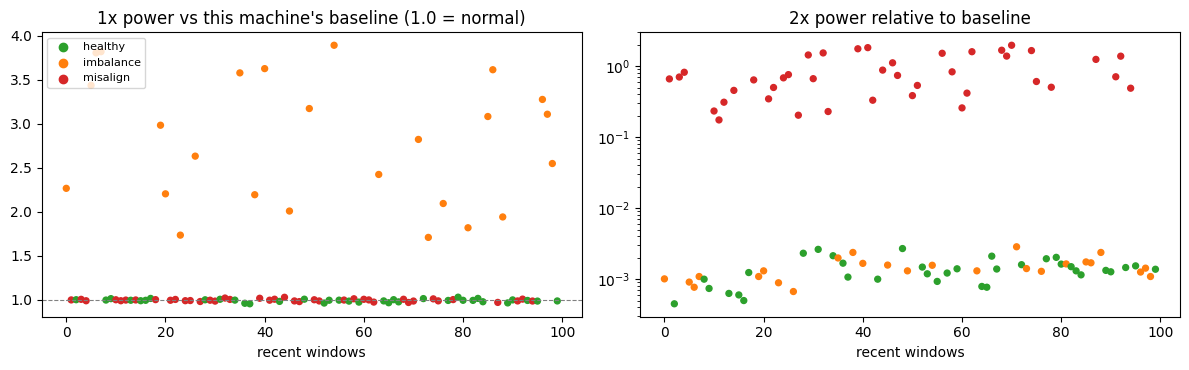


Confusion matrix (rows = simulator label, columns = prediction):
           healthy  imbalance  misalign
healthy         55          0         0
imbalance        0         40         0
misalign         0          0        65


In [ ]:
!pip -q install paho-mqtt

import json, time, collections
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import paho.mqtt.client as mqtt
from IPython.display import clear_output
from sklearn.metrics import confusion_matrix

MODEL_FILE  = "vib_model_calibrated.joblib"
TOPIC       = "vibmon_AJ_4827/node1/features"
FEATURES    = ["rms_n", "p1x_n", "p2x_n", "p3x_n", "kurt", "crest", "ratio"]
LABELS      = ["healthy", "imbalance", "misalign"]
COLORS      = {"healthy": "tab:green", "imbalance": "tab:orange", "misalign": "tab:red"}
DURATION    = 600        # seconds to run the live monitor
ALERT_AFTER = 3          # consecutive fault windows before an alert is raised
SHOW_LAST   = 100        # windows shown in the plots

model = joblib.load(MODEL_FILE)
inbox = collections.deque()

def on_connect(client, userdata, flags, reason_code, properties=None):
    client.subscribe(TOPIC)

def on_message(client, userdata, m):
    try:
        inbox.append(json.loads(m.payload.decode()))
    except Exception:
        pass

client = mqtt.Client(mqtt.CallbackAPIVersion.VERSION2)
client.on_connect = on_connect
client.on_message = on_message
client.connect("broker.hivemq.com", 1883, 60)
client.loop_start()

history, alerts = [], []
streak, last_machine = 0, None
status = "waiting for data..."
last_draw = 0.0

def draw():
    clear_output(wait=True)
    print("STATUS :", status)
    if history:
        agree = np.mean([h["pred"] == h["truth"] for h in history])
        print(f"Windows classified: {len(history)}   "
              f"agreement with the simulator's label (demo only): {agree:.1%}")
    print("ALERTS :", len(alerts))
    for a in alerts[-5:]:
        print("   ", a)
    if history:
        h = pd.DataFrame(history[-SHOW_LAST:])
        colors = [COLORS[p] for p in h["pred"]]
        fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
        ax[0].scatter(range(len(h)), h["p1x_n"], c=colors, s=18)
        ax[0].axhline(1.0, color="gray", lw=0.8, ls="--")
        ax[0].set_title("1x power vs this machine's baseline (1.0 = normal)")
        ax[1].scatter(range(len(h)), h["p2x_n"].clip(lower=1e-4), c=colors, s=18)
        ax[1].set_yscale("log")
        ax[1].set_title("2x power relative to baseline")
        for a_ in ax:
            a_.set_xlabel("recent windows")
        for lab, col in COLORS.items():
            ax[0].scatter([], [], c=col, label=lab)
        ax[0].legend(loc="upper left", fontsize=8)
        plt.tight_layout()
        plt.show()

t0 = time.time()
try:
    while time.time() - t0 < DURATION:
        while inbox:
            d = inbox.popleft()
            if d.get("machine") != last_machine:        # new machine: reset the streak
                last_machine = d.get("machine")
                streak = 0
            if d.get("phase") == "cal":
                status = f"machine {d['machine']}: calibrating, learning the healthy baseline"
                continue
            x = pd.DataFrame([[d[c] for c in FEATURES]], columns=FEATURES)
            pred = model.predict(x)[0]
            streak = streak + 1 if pred != "healthy" else 0
            if streak == ALERT_AFTER:
                alerts.append(f"machine {d['machine']}, window {d['n']}: "
                              f"{pred.upper()} ({ALERT_AFTER} windows in a row)")
            if streak >= ALERT_AFTER:
                status = f"machine {d['machine']}: ALERT - {pred}"
            elif streak > 0:
                status = f"machine {d['machine']}: suspect - {pred}"
            else:
                status = f"machine {d['machine']}: OK"
            history.append(dict(n=d["n"], machine=d["machine"], pred=pred,
                                truth=d["truth"], p1x_n=d["p1x_n"], p2x_n=d["p2x_n"]))
        if time.time() - last_draw > 2:
            draw()
            last_draw = time.time()
        time.sleep(0.5)
except KeyboardInterrupt:
    print("Stopped by user")
finally:
    client.loop_stop()
    client.disconnect()

draw()
if history:
    h = pd.DataFrame(history)
    print("\nConfusion matrix (rows = simulator label, columns = prediction):")
    print(pd.DataFrame(confusion_matrix(h["truth"], h["pred"], labels=LABELS),
                       index=LABELS, columns=LABELS))

In [ ]:
# from google.colab import files
# up = files.upload()          # a file picker opens: choose vib_model_calibrated.joblib
# print(list(up.keys()))